# Vehicle Registration Forecast

**Data Science Challenge** · Author: Solano Jacon

Forecast monthly new-vehicle registrations in Brazil 1 to 6 months ahead, for the total market and for each segment (passenger cars, light commercials, trucks and buses). [Challenge description](README.md).

**Summary**

- The series covers **January 2002 to March 2021** (ANFAVEA). Every forecast uses only the information that would have been published on the day it is made.
- Four models and two naive baselines were compared on a development period (forecasts for October 2012 to March 2018), forecasting from every month as if in real time. **Exponential smoothing (ETS)** on registrations per working day was the most accurate, and it was chosen before looking at the test period.
- On the test period (April 2018 to March 2021), outside the pandemic shock, ETS misses by **4.8% one month ahead and 11.7% six months ahead**. Its average error is **8.7%, about 40% lower than repeating the last month (14.6%)** and about 15% lower than repeating the same month of the previous year (10.3%).
- No model anticipated the collapse of March–August 2020. IBGE's industry and retail indicators, used with their real publication delay, improved the regression model only slightly. They did not beat ETS in the development period, where the model was chosen, and were only marginally ahead on the test period (8.2% vs 8.7%).
- ETS also beats the naive forecasts for every segment. Buses are the hardest segment to forecast.

**Contents**

1. Data reading and preparation
2. Exploratory analysis
3. Forecasting setup
4. Candidate models
5. Model choice
6. Test results
7. Segments
8. Forecast for April–September 2021
9. Conclusions and next steps

## Setup

In [1]:
import warnings
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', EstimationWarning)

DATA_DIR = '../../portfolio-data/Vehicle_Registration_Forecast/data/'
START, END = '2002-01-01', '2021-03-01'          # months used
HORIZON = 6                                      # forecast 1 to 6 months ahead
DEV_TARGETS = ('2012-10-01', '2018-03-01')       # months used to choose the model
TEST_TARGETS = ('2018-04-01', '2021-03-01')      # last 36 months, evaluated once
SHOCK = ('2020-03-01', '2020-08-01')             # pandemic shock, reported separately

In [2]:
# Chart style
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985'
INK, INK_2, GRID, SURFACE, BAND = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb', '#f1f0ec'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10, 'legend.frameon': False,
    'lines.linewidth': 2,
})
pct = lambda x, d=1: f'{x:.{d}%}'
thousands = plt.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k')


def end_labels(ax, x, values, labels, min_gap):
    """Label lines at their right end, nudging labels apart so they don't overlap."""
    order = np.argsort(values)
    placed = []
    for i in order:
        y = values[i] if not placed else max(values[i], placed[-1] + min_gap)
        placed.append(y)
        ax.annotate(labels[i], (x, values[i]), xytext=(x, y), textcoords='data',
                    xycoords='data', ha='left', va='center', color=INK_2, fontsize=9)

## 1. Data reading and preparation

### 1.1 Sources and publication dates

| Source | Series | Monthly since | Published |
| --- | --- | --- | --- |
| ANFAVEA | Registrations (*licenciamento*) by segment | 1957 | first days of the next month |
| IBGE PIM-PF, table 3653 | Industrial production index, general industry | 2002 | about 5 weeks after the month ends |
| IBGE PMC, table 3416 | Retail sales volume index | 2000 | about 6 weeks after the month ends |
| IBGE PMS, table 6442 | Services volume index | 2011 | about 6 weeks after the month ends |
| IBGE LSPA, table 6588 | Harvested area, annual estimate revised monthly | 2006 | during the month |
| IBGE IPCA, table 1737 | Consumer price index (index number) | 1979 | about 10 days after the month ends |

The publication dates matter. A forecast made at the start of a month knows the previous month's registrations, but the IBGE activity indices only up to **two months earlier**. Using an index for a month that hasn't been published yet would make the backtest look better than any real forecast could be.

### 1.2 Registrations (ANFAVEA)

In [3]:
raw = pd.read_excel(DATA_DIR + 'ANFAVEA_SeriesTemporais_Autoveiculos.xlsm', header=None)

SEGMENTS = {1: 'total', 6: 'cars', 11: 'light_commercials', 16: 'trucks', 21: 'buses'}
raw.iloc[2:5, list(SEGMENTS)]   # header rows: segment and variable of each column

,1,6,11,16,21
2,2050317,1688289,300307,50560,11161
3,AUTOVEÍCULOS TOTAL,AUTOMÓVEIS,COMERCIAIS LEVES,CAMINHÕES,ÔNIBUS
4,Licenciamento Total,Licenciamento Total,Licenciamento Total,Licenciamento Total,Licenciamento Total


In [4]:
registrations = raw.iloc[5:, [0, *SEGMENTS]]
registrations.columns = ['month', *SEGMENTS.values()]
registrations = (registrations.set_index(pd.to_datetime(registrations['month']))
                 .drop(columns='month').astype(float))

print(f'File covers {registrations.index.min():%b/%Y} to {registrations.index.max():%b/%Y}; '
      f'{(registrations["total"] == 0).sum()} months at the end are still empty.')

registrations = registrations.loc[START:END].asfreq('MS')
segments = ['cars', 'light_commercials', 'trucks', 'buses']
print(f'Used: {registrations.index.min():%b/%Y} to {registrations.index.max():%b/%Y}, '
      f'{len(registrations)} months, no missing values: {registrations.notna().all().all()}')
print('Segments add up to the total:', (registrations[segments].sum(axis=1) == registrations['total']).all())
registrations.tail()

File covers Jan/1957 to Dec/2021; 8 months at the end are still empty.
Used: Jan/2002 to Mar/2021, 231 months, no missing values: True
Segments add up to the total: True


,total,cars,light_commercials,trucks,buses
month,,,,,
2020-11-01,225010.0,177577.0,36909.0,9143.0,1381.0
2020-12-01,243967.0,194681.0,38303.0,9838.0,1145.0
2021-01-01,171146.0,130804.0,31776.0,7537.0,1029.0
2021-02-01,167391.0,128111.0,30377.0,7781.0,1122.0
2021-03-01,189389.0,141952.0,35498.0,10759.0,1180.0


Until 2001 ANFAVEA reported wholesale sales instead of registrations, so the series starts in January 2002. The months after March 2021 are left out.

### 1.3 Economic indicators (IBGE)

The SIDRA tables have a few header rows and the months written in Portuguese (`março 2021`).

In [5]:
MONTHS_PT = {'janeiro': 1, 'fevereiro': 2, 'março': 3, 'abril': 4, 'maio': 5, 'junho': 6,
             'julho': 7, 'agosto': 8, 'setembro': 9, 'outubro': 10, 'novembro': 11, 'dezembro': 12}


def read_sidra(file, name):
    table = pd.read_excel(DATA_DIR + file, header=None).iloc[:, :2]
    label = table[0].astype(str).str.split()
    table = table[label.str[0].isin(MONTHS_PT)]
    label = table[0].str.split()
    index = pd.to_datetime([f'{y}-{MONTHS_PT[m]:02d}-01' for m, y in label])
    return pd.Series(pd.to_numeric(table[1], errors='coerce').values, index=index, name=name)


indicators = pd.concat([
    read_sidra('IBGE_PIMPF_tabela3653.xlsx', 'industry'),
    read_sidra('IBGE_PMC_tabela3416.xlsx', 'retail'),
    read_sidra('IBGE_PMS_tabela6442.xlsx', 'services'),
    read_sidra('IBGE_LSPA_tabela6588.xlsx', 'harvested_area'),
    read_sidra('IBGE_IPCA_tabela1737.xlsx', 'consumer_prices'),
], axis=1, sort=True).loc[:END]

pd.DataFrame({'first month': indicators.apply(lambda s: f'{s.first_valid_index():%b/%Y}'),
              'last month': indicators.apply(lambda s: f'{s.last_valid_index():%b/%Y}'),
              'missing in between': indicators.apply(lambda s: s.loc[s.first_valid_index():].isna().sum())})

,first month,last month,missing in between
industry,Jan/2002,Mar/2021,0
retail,Jan/2000,Mar/2021,0
services,Jan/2011,Mar/2021,0
harvested_area,Sep/2006,Mar/2021,0
consumer_prices,Dec/1979,Mar/2021,0


Only **industry** and **retail** go into the models:

- **Services** starts in 2011, too late to train and evaluate models from 2012 onwards.
- **Harvested area** is an estimate of the whole year's crop, revised every month. It is not a measure of activity in a given month.
- **Consumer prices** is a price level that only goes up. It would matter as a deflator, not on its own.

### 1.4 Working days

A month with fewer working days has fewer registrations. Because of February, Carnival and other holidays, a month has between 18 and 23 working days, a difference of more than 25%. Working days are counted Monday to Friday, minus national holidays. Carnival Monday and Tuesday and Corpus Christi are optional holidays (*pontos facultativos*) and are also counted as days off.

In [6]:
def easter(year):
    """Gregorian Easter Sunday (anonymous algorithm)."""
    a, b, c = year % 19, year // 100, year % 100
    d, e = divmod(b, 4)
    g = (8 * b + 13) // 25
    h = (19 * a + b - d - g + 15) % 30
    i, k = divmod(c, 4)
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    month, day = divmod(h + l - 7 * m + 114, 31)
    return date(year, month, day + 1)


def national_holidays(year):
    fixed = [(1, 1), (4, 21), (5, 1), (9, 7), (10, 12), (11, 2), (11, 15), (12, 25)]
    e = easter(year)
    movable = [e - timedelta(days=48), e - timedelta(days=47),   # Carnival Monday and Tuesday
               e - timedelta(days=2), e + timedelta(days=60)]    # Good Friday, Corpus Christi
    return [date(year, m, d) for m, d in fixed] + movable


HOLIDAYS = [d for year in range(2002, 2023) for d in national_holidays(year)]
calendar_months = pd.date_range(START, pd.Timestamp(END) + pd.DateOffset(months=HORIZON), freq='MS')
working_days = pd.Series(
    [np.busday_count(m.date(), (m + pd.offsets.MonthBegin()).date(), holidays=HOLIDAYS) for m in calendar_months],
    index=calendar_months, name='working_days')

pd.DataFrame({year: working_days.loc[str(year)].values for year in [2019, 2020]},
             index=[f'{m:%b}' for m in working_days.loc['2019'].index]).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2019,22,20,19,21,22,19,23,22,21,23,20,21
2020,22,18,22,20,20,21,23,21,21,21,20,22


## 2. Exploratory analysis

### 2.1 The level moves with the economy

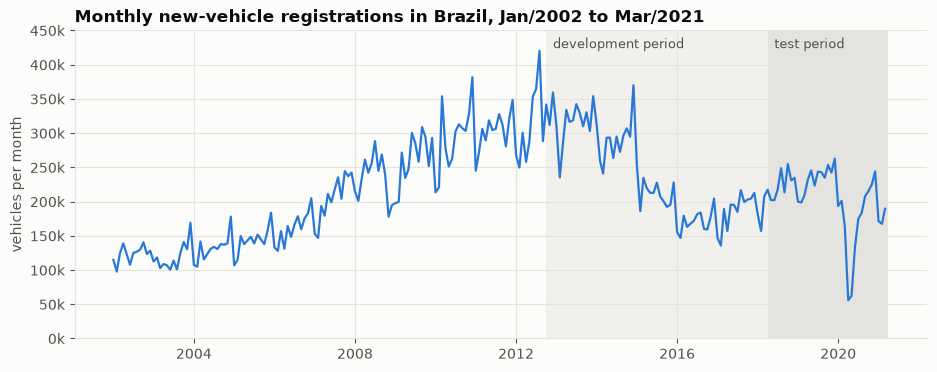

month,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
million vehicles,1.48,1.43,1.58,1.71,1.93,2.46,2.82,3.14,3.52,3.63,3.8,3.77,3.5,2.57,2.05,2.24,2.57,2.79,2.06


In [7]:
total = registrations['total']
fig, ax = plt.subplots(figsize=(11, 4))
for (start, end), label, shade in [(DEV_TARGETS, 'development period', BAND), (TEST_TARGETS, 'test period', GRID)]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.offsets.MonthEnd(), color=shade, lw=0, zorder=0)
    ax.text(pd.Timestamp(start) + pd.DateOffset(months=2), 440_000, label, color=INK_2, fontsize=9, va='top')
ax.plot(total.index, total, color=BLUE, lw=1.6)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, 450_000)
ax.set_title('Monthly new-vehicle registrations in Brazil, Jan/2002 to Mar/2021')
ax.set_ylabel('vehicles per month')
plt.show()

annual = registrations.resample('YS').sum().loc[:'2020']
annual.index = annual.index.year
(annual[['total']] / 1e6).T.round(2).rename(index={'total': 'million vehicles'})

- Registrations almost tripled from 2003 (1.4 million) to the 2012 peak (3.8 million). They fell to about half of that in the 2015–2016 recession (2.05 million in 2016) and recovered to 2.79 million in 2019.
- In April 2020, the first full month of the pandemic, registrations fell **76% from April 2019** to 56 thousand. They were back to pre-pandemic levels by the end of the year, but 2020 still closed 26% below 2019.
- Long swings and sudden shocks dominate the series. A model has to follow the recent level quickly, not just repeat a long-term average.

### 2.2 Seasonality and working days

The seasonal pattern is measured by comparing each month with a centered 12-month average. Only the years before the test period are used (2003–2017).

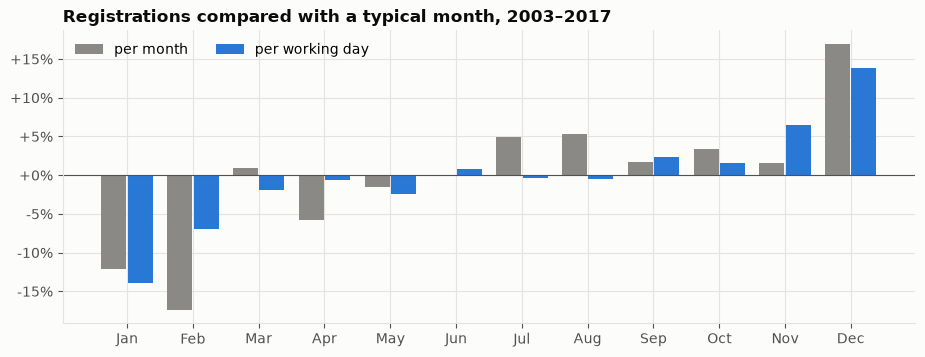

Spread of the seasonal effects: 8.8% per month, 6.7% per working day


In [8]:
def seasonal_profile(series):
    trend = series.rolling(12, center=True).mean().rolling(2).mean().shift(-1)   # centered 2x12 average
    ratio = (series / trend).loc['2003':'2017']
    return ratio.groupby(ratio.index.month).mean() - 1


per_working_day = total / working_days[total.index]
profile = pd.DataFrame({'per month': seasonal_profile(total), 'per working day': seasonal_profile(per_working_day)})

fig, ax = plt.subplots(figsize=(11, 3.8))
x, width = np.arange(12), 0.38
ax.bar(x - width / 2 - 0.01, profile['per month'], width, color=GRAY, label='per month')
ax.bar(x + width / 2 + 0.01, profile['per working day'], width, color=BLUE, label='per working day')
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(x, [f'{pd.Timestamp(2020, m, 1):%b}' for m in range(1, 13)])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.0%}'))
ax.set_title('Registrations compared with a typical month, 2003–2017')
ax.legend(loc='upper left', ncol=2)
plt.show()

print(f"Spread of the seasonal effects: {profile['per month'].std():.1%} per month, "
      f"{profile['per working day'].std():.1%} per working day")

- December is the strongest month (+17%) and January and February the weakest.
- Most of the weakness in February comes from short months and Carnival. Per working day, February is only 7% below a typical month instead of 17%.
- Dividing by working days takes out about a quarter of the seasonal variation (8.8% → 6.7%). The models therefore forecast **registrations per working day**, and the result is multiplied back by the working days of the month forecast. The calendar of future months is known in advance.

### 2.3 Segments

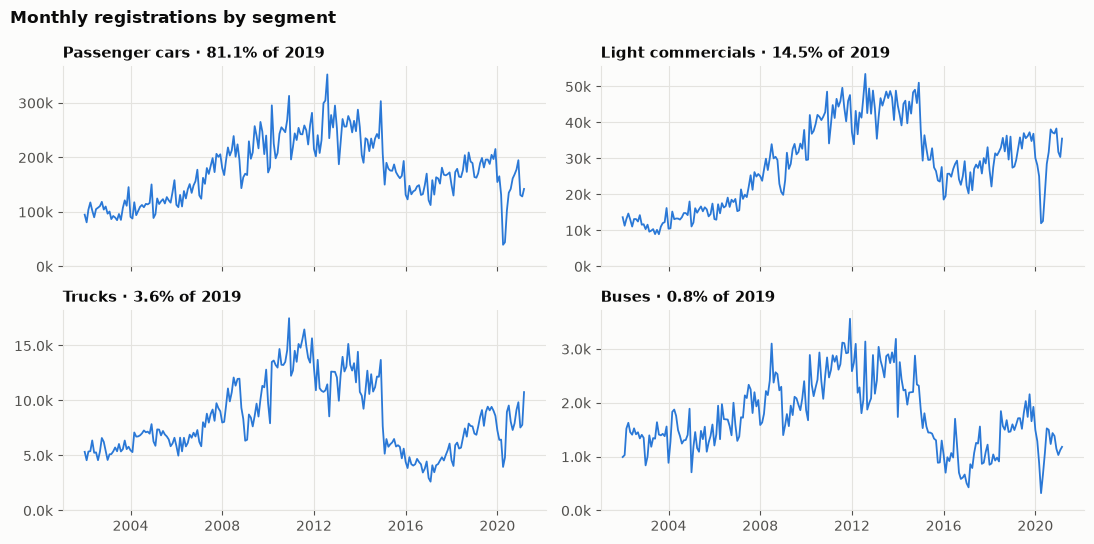

In [9]:
share_2019 = registrations.loc['2019', segments].sum() / registrations.loc['2019', 'total'].sum()
names = {'cars': 'Passenger cars', 'light_commercials': 'Light commercials', 'trucks': 'Trucks', 'buses': 'Buses'}

fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), sharex=True)
for ax, seg in zip(axes.flat, segments):
    ax.plot(registrations.index, registrations[seg], color=BLUE, lw=1.3)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(thousands if registrations[seg].max() > 20_000
                                 else plt.FuncFormatter(lambda v, _: f'{v / 1000:,.1f}k'))
    ax.set_title(f'{names[seg]} · {share_2019[seg]:.1%} of 2019', fontsize=11)
fig.suptitle('Monthly registrations by segment', x=0.01, ha='left', fontweight='bold', color=INK)
fig.tight_layout()
plt.show()

- **Passenger cars** are 81% of the market and drive the total.
- **Light commercials** follow a similar path.
- **Trucks** depend on investment and agribusiness. They fell further in the recession (from 173 thousand in 2011 to 51 thousand in 2016) and recovered faster after it.
- **Buses** sell fewer than 2,000 units a month, so a single large fleet order moves the series. This will make them the hardest segment to forecast.

## 3. Forecasting setup

**When a forecast is made.** A forecast is made at the start of month *t + 1*, as soon as ANFAVEA publishes month *t*. Each forecast covers months *t + 1* to *t + 6* (horizons 1 to 6).

**What is known at that moment.**
- Registrations up to month *t*.
- The IBGE indices up to month *t − 2*.
- The working days of every month, including future ones.

**Rolling-origin backtest.** The test repeats that situation for every month. At each origin, every model is refit using only data up to the origin and forecasts the next 6 months. The forecasts are then compared with what happened. This gives up to six forecasts, from different origins, for every target month.

| Period | Target months | Used for |
| --- | --- | --- |
| Development | Oct/2012 to Mar/2018 | comparing models and choosing one |
| Test | Apr/2018 to Mar/2021 | measuring the chosen model, once |

**Metric.** The metric is the mean absolute percentage error (**MAPE**) for each horizon, which reads directly as "the forecast misses by X%". In the test period, March–August 2020 is also reported apart: a shock of that size is not something a monthly forecast can be expected to see coming, and those six months would otherwise dominate the averages.

## 4. Candidate models

| Model | Idea |
| --- | --- |
| Naive | next months = last month |
| Seasonal naive | each month = same month one year earlier |
| ETS | exponential smoothing with damped trend and seasonality (Holt-Winters) |
| SARIMA | seasonal ARIMA (1,1,1)(0,1,1)<sub>12</sub>, the classic "airline" structure plus an AR term |
| Ridge | one regression per horizon on the last 12 months, the same month last year, calendar month and working days |
| Ridge + IBGE indicators | the same, plus the 3- and 12-month changes in industry and retail, as published at the origin |

The naive and seasonal naive forecasts are the baselines that any model has to beat. ETS, SARIMA and Ridge work on the log of registrations per working day.

In [10]:
def to_model_scale(series):
    return np.log(series / working_days[series.index]).asfreq('MS')


def future_months(origin):
    return pd.date_range(origin + pd.DateOffset(months=1), periods=HORIZON, freq='MS')


def to_vehicles(log_per_day, origin):
    return np.exp(np.asarray(log_per_day)) * working_days[future_months(origin)].values


def forecast_naive(series, origin):
    return np.repeat(series[origin], HORIZON)


def forecast_seasonal_naive(series, origin):
    return series[future_months(origin) - pd.DateOffset(months=12)].values


def forecast_ets(series, origin):
    z = to_model_scale(series[:origin])
    fit = ExponentialSmoothing(z, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit()
    return to_vehicles(fit.forecast(HORIZON), origin)


def forecast_sarima(series, origin):
    z = to_model_scale(series[:origin])
    fit = SARIMAX(z, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return to_vehicles(fit.forecast(HORIZON), origin)

The Ridge models are *direct*: one regression per horizon. Row *o* of the feature table only uses data up to month *o*, and the IBGE indices only up to *o − 2*. A model fit at origin *t* for horizon *h* is trained only on rows whose target, *o + h*, is no later than *t*. The penalty is chosen by efficient leave-one-out cross-validation, which is valid for autoregressive models like this one (Bergmeir, Hyndman & Koo, 2018).

In [11]:
_feature_cache = {}


def ridge_features(series, h, use_indicators):
    key = (series.name, h, use_indicators)
    if key not in _feature_cache:
        z = to_model_scale(series)
        target_month = z.index + pd.DateOffset(months=h)
        X = pd.DataFrame({f'lag_{k}': z.shift(k) for k in range(12)})
        X['same_month_last_year'] = z.shift(12 - h)
        X['log_working_days'] = np.log(working_days.reindex(target_month).values)
        for m in range(1, 13):
            X[f'month_{m}'] = (target_month.month == m).astype(float)
        if use_indicators:
            log_ind = np.log(indicators[['industry', 'retail']]).reindex(z.index)
            for col in log_ind:
                published = log_ind[col].shift(2)          # last month published at the origin
                X[f'{col}_change_12m'] = published - published.shift(12)
                X[f'{col}_change_3m'] = published - published.shift(3)
        _feature_cache[key] = (X, z.shift(-h))
    return _feature_cache[key]


def forecast_ridge(series, origin, use_indicators=False):
    predictions = []
    for h in range(1, HORIZON + 1):
        X, y = ridge_features(series, h, use_indicators)
        train = (X.index <= origin - pd.DateOffset(months=h)) & X.notna().all(axis=1) & y.notna()
        model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25)))
        model.fit(X[train], y[train])
        predictions.append(model.predict(X.loc[[origin]])[0])
    return to_vehicles(predictions, origin)


MODELS = {
    'Naive': forecast_naive,
    'Seasonal naive': forecast_seasonal_naive,
    'ETS': forecast_ets,
    'SARIMA': forecast_sarima,
    'Ridge': forecast_ridge,
    'Ridge + IBGE indicators': lambda s, o: forecast_ridge(s, o, use_indicators=True),
}

In [12]:
def backtest(series, models, first_target, last_target):
    first_target, last_target = pd.Timestamp(first_target), pd.Timestamp(last_target)
    origins = pd.date_range(first_target - pd.DateOffset(months=HORIZON),
                            last_target - pd.DateOffset(months=1), freq='MS')
    rows = []
    for origin in origins:
        months = future_months(origin)
        for name, forecast in models.items():
            for h, (month, value) in enumerate(zip(months, forecast(series, origin)), start=1):
                if first_target <= month <= last_target:
                    rows.append((name, origin, h, month, value, series[month]))
    result = pd.DataFrame(rows, columns=['model', 'origin', 'horizon', 'month', 'forecast', 'actual'])
    result['ape'] = (result['forecast'] / result['actual'] - 1).abs()
    result['period'] = np.where(result['month'] >= pd.Timestamp(TEST_TARGETS[0]), 'test', 'development')
    result['shock'] = result['month'].between(*SHOCK)
    return result


def mape_table(result):
    table = result.pivot_table(index='model', columns='horizon', values='ape', aggfunc='mean')
    table.columns = [f'{h} month' + ('s' if h > 1 else '') for h in table.columns]
    table['average'] = table.mean(axis=1)
    return table.sort_values('average')


show = lambda table: table.map(pct)

In [13]:
results = backtest(total, MODELS, DEV_TARGETS[0], TEST_TARGETS[1])
print(f"{results['origin'].nunique()} origins, {len(results):,} forecasts")

107 origins, 3,672 forecasts


## 5. Model choice

MAPE by horizon in the development period (target months October 2012 to March 2018):

In [14]:
dev = results[results['period'] == 'development']
dev_table = mape_table(dev)
show(dev_table)

,1 month,2 months,3 months,4 months,5 months,6 months,average
model,,,,,,,
ETS,5.2%,7.9%,9.0%,9.7%,10.9%,12.2%,9.2%
Ridge + IBGE indicators,6.2%,8.7%,9.7%,11.3%,12.9%,14.2%,10.5%
SARIMA,6.2%,9.2%,10.9%,12.4%,13.9%,15.7%,11.4%
Ridge,6.6%,9.6%,10.9%,12.0%,13.6%,15.5%,11.4%
Naive,12.0%,14.2%,14.1%,14.6%,16.1%,17.7%,14.8%
Seasonal naive,18.0%,18.0%,18.0%,18.0%,18.0%,18.0%,18.0%


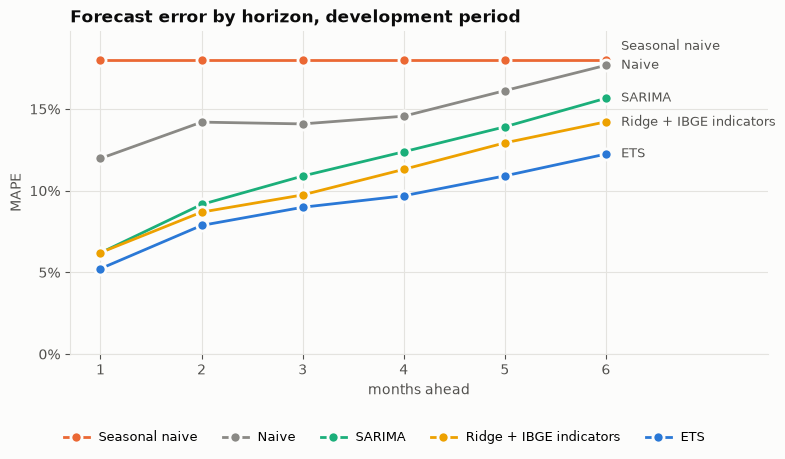

In [15]:
def plot_mape_by_horizon(table, models, colors, title, ax):
    x = np.arange(1, HORIZON + 1)
    for model, color in zip(models, colors):
        ax.plot(x, table.loc[model].iloc[:HORIZON], color=color, marker='o', ms=8,
                markeredgecolor=SURFACE, markeredgewidth=2)
    end_labels(ax, HORIZON + 0.15, table.loc[models].iloc[:, HORIZON - 1].values, models,
               min_gap=(ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.06)
    ax.set_xticks(x, [f'{h}' for h in x])
    ax.set_xlim(0.7, HORIZON + 1.6)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_xlabel('months ahead')
    ax.legend(models, loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=len(models), fontsize=9)
    ax.set_ylabel('MAPE')
    ax.set_title(title)


chart_models = ['Seasonal naive', 'Naive', 'SARIMA', 'Ridge + IBGE indicators', 'ETS']
chart_colors = [ORANGE, GRAY, AQUA, YELLOW, BLUE]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.set_ylim(0, dev_table.loc[chart_models].max().max() * 1.1)
plot_mape_by_horizon(dev_table, chart_models, chart_colors, 'Forecast error by horizon, development period', ax)
plt.show()

- **All models beat both baselines at every horizon.** The seasonal naive is the worst: in a series with long swings, last year's level is often far from this year's.
- **ETS is the most accurate at every horizon**, from 5.2% one month ahead to 12.2% six months ahead. It is chosen as the forecasting model.
- The IBGE indicators improve the Ridge model a little (10.5% vs 11.4% on average), but not enough to catch ETS. Most of what they say about the economy is already in the recent registrations by the time they are published.

## 6. Test results

The test period (April 2018 to March 2021) is used only now, with the choice already made. All models are shown for transparency.

In [16]:
test = results[results['period'] == 'test']
outside = mape_table(test[~test['shock']])
print('Outside the shock (March–August 2020 excluded)')
display(show(outside))
print('All test months')
display(show(mape_table(test)))

Outside the shock (March–August 2020 excluded)


,1 month,2 months,3 months,4 months,5 months,6 months,average
model,,,,,,,
Ridge + IBGE indicators,5.0%,7.3%,8.6%,9.6%,9.5%,9.5%,8.2%
SARIMA,4.6%,6.1%,6.9%,9.5%,12.0%,12.4%,8.6%
ETS,4.8%,6.3%,7.3%,10.1%,11.7%,11.7%,8.7%
Ridge,5.7%,8.8%,9.4%,10.3%,10.6%,10.2%,9.2%
Seasonal naive,10.3%,10.3%,10.3%,10.3%,10.3%,10.3%,10.3%
Naive,9.3%,12.4%,14.9%,16.0%,17.7%,17.4%,14.6%


All test months


,1 month,2 months,3 months,4 months,5 months,6 months,average
model,,,,,,,
Ridge + IBGE indicators,14.0%,23.8%,26.2%,28.2%,28.4%,28.7%,24.9%
Ridge,13.9%,24.7%,27.5%,28.9%,29.6%,29.7%,25.7%
ETS,13.9%,24.1%,27.2%,29.1%,30.0%,30.4%,25.8%
SARIMA,13.6%,24.0%,27.1%,28.9%,30.2%,31.0%,25.8%
Seasonal naive,30.3%,30.3%,30.3%,30.3%,30.3%,30.3%,30.3%
Naive,16.3%,26.8%,31.5%,34.4%,36.5%,36.8%,30.4%


In [17]:
ets_test = test[(test['model'] == 'ETS') & ~test['shock']].copy()
ets_test['abs_error'] = (ets_test['forecast'] - ets_test['actual']).abs()
summary = ets_test.groupby('horizon').agg(MAPE=('ape', 'mean'), MAE=('abs_error', 'mean'))
naive_mape = test[(test['model'] == 'Naive') & ~test['shock']].groupby('horizon')['ape'].mean()
summary['MAPE naive'] = naive_mape
summary['error reduction vs naive'] = 1 - summary['MAPE'] / summary['MAPE naive']
summary.style.format({'MAPE': pct, 'MAPE naive': pct, 'error reduction vs naive': pct, 'MAE': '{:,.0f} vehicles'})

,MAPE,MAE,MAPE naive,error reduction vs naive
horizon,,,,
1,4.8%,"10,500 vehicles",9.3%,48.7%
2,6.3%,"13,726 vehicles",12.4%,48.9%
3,7.3%,"15,912 vehicles",14.9%,50.8%
4,10.1%,"21,990 vehicles",16.0%,37.1%
5,11.7%,"25,464 vehicles",17.7%,33.8%
6,11.7%,"25,652 vehicles",17.4%,32.4%


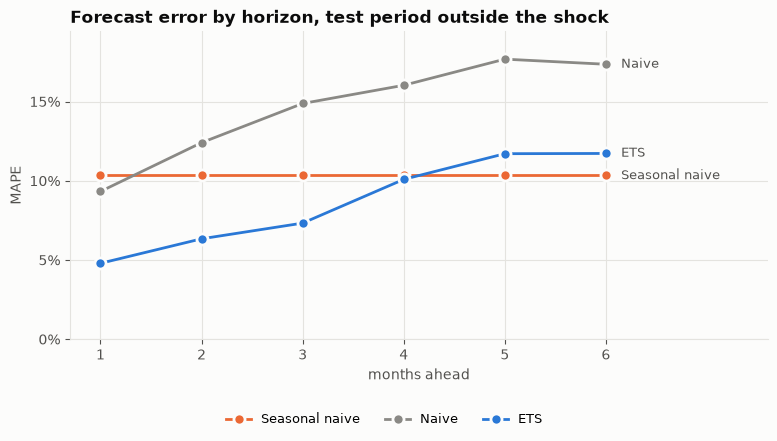

In [18]:
models_3 = ['Seasonal naive', 'Naive', 'ETS']
fig, ax = plt.subplots(figsize=(9, 4))
ax.set_ylim(0, outside.loc[models_3].max().max() * 1.1)
plot_mape_by_horizon(outside, models_3, [ORANGE, GRAY, BLUE], 'Forecast error by horizon, test period outside the shock', ax)
plt.show()

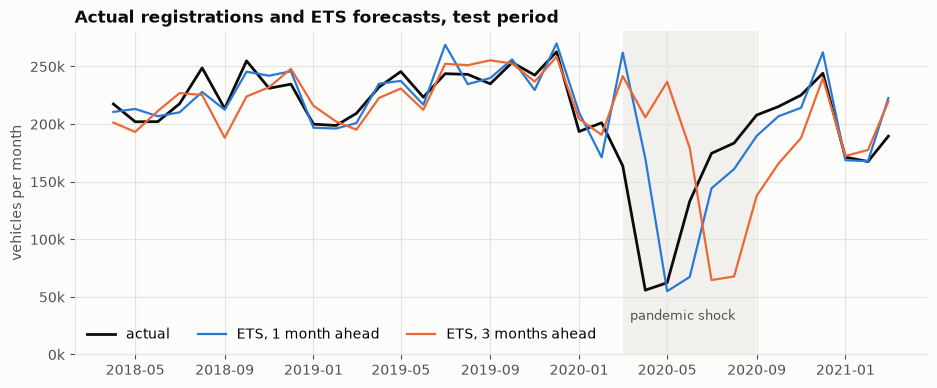

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(pd.Timestamp(SHOCK[0]), pd.Timestamp(SHOCK[1]) + pd.offsets.MonthEnd(), color=BAND, lw=0, zorder=0)
ax.text(pd.Timestamp(SHOCK[0]) + pd.DateOffset(days=10), 30_000, 'pandemic shock', color=INK_2, fontsize=9)
actual = total.loc[TEST_TARGETS[0]:]
ax.plot(actual.index, actual, color=INK, lw=2, label='actual')
for h, color in [(1, BLUE), (3, ORANGE)]:
    f = test[(test['model'] == 'ETS') & (test['horizon'] == h)].set_index('month')['forecast']
    ax.plot(f.index, f, color=color, lw=1.6, label=f'ETS, {h} month{"s" if h > 1 else ""} ahead')
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, None)
ax.set_title('Actual registrations and ETS forecasts, test period')
ax.set_ylabel('vehicles per month')
ax.legend(loc='lower left', ncol=3)
plt.show()

- **Outside the shock**, ETS misses by **4.8% one month ahead** (about 10 thousand vehicles) and **11.7% six months ahead** (about 26 thousand). Its average error is **8.7%, 40% lower than the naive forecast (14.6%)** and about 15% lower than the seasonal naive (10.3%).
- In this calm stretch (2018–2019), the seasonal naive catches up with ETS from 4 months ahead. When the market grows steadily, last year's month is a good guess. In the development period, which had a boom and a recession, it was by far the worst model.
- The top models end up close on the test period. Ridge + IBGE indicators is slightly ahead outside the shock (8.2% against 8.7%), and the differences are small next to the month-to-month noise. The choice made in the development period stands.
- **The pandemic** is visible in the chart. No model saw April 2020 coming, and all of them then took a few months to follow the recovery. Including those months, every model's average error rises above 24%. ETS (25.8%) is still ahead of the naive forecast (30.4%).

## 7. Segments

The chosen model is now applied to each segment and compared with the baselines on the test period.

In [20]:
segment_models = {name: MODELS[name] for name in ['Naive', 'Seasonal naive', 'ETS']}
segment_rows = {}
for seg in segments:
    r = backtest(registrations[seg], segment_models, *TEST_TARGETS)
    outside_shock = mape_table(r[~r['shock']])
    segment_rows[names[seg]] = {
        'ETS, 1 month': outside_shock.loc['ETS', '1 month'],
        'ETS, 6 months': outside_shock.loc['ETS', '6 months'],
        'ETS, average': outside_shock.loc['ETS', 'average'],
        'Naive, average': outside_shock.loc['Naive', 'average'],
        'Seasonal naive, average': outside_shock.loc['Seasonal naive', 'average'],
        'ETS, average incl. shock': mape_table(r).loc['ETS', 'average'],
    }
segment_table = pd.DataFrame(segment_rows).T
show(segment_table)

,"ETS, 1 month","ETS, 6 months","ETS, average","Naive, average","Seasonal naive, average","ETS, average incl. shock"
Passenger cars,5.3%,11.9%,9.3%,15.1%,10.7%,29.4%
Light commercials,6.0%,14.0%,9.8%,14.9%,9.9%,20.7%
Trucks,5.6%,14.9%,10.4%,14.6%,23.9%,15.7%
Buses,12.3%,20.1%,16.6%,19.0%,28.7%,35.3%


MAPE on the test period, outside the shock unless noted:

- ETS beats the naive forecast for every segment.
- **Passenger cars and light commercials** behave like the total: about 9–10% average error. In this calm period the seasonal naive is close behind.
- **Trucks** are where ETS helps most against the seasonal naive (10.4% against 23.9%). Truck sales grew fast in 2018–2019, so last year's level was always too low.
- **Buses** are the hardest segment (16.6%). With fewer than 2,000 units a month, individual fleet orders and public tenders move the series in ways that the history cannot anticipate.

## 8. Forecast for April–September 2021

ETS is fit on the full history up to March 2021. The range shown is the 10th–90th percentile of ETS's own backtest errors at each horizon, over development and test, pandemic included. Eight in ten past forecasts fell inside such a range.

In [21]:
ets_errors = results[results['model'] == 'ETS'].assign(log_error=lambda d: np.log(d['actual'] / d['forecast']))
error_quantiles = ets_errors.groupby('horizon')['log_error'].quantile([0.1, 0.9]).unstack()

origin = total.index[-1]
months = future_months(origin)
forecast = pd.DataFrame({'working days': working_days[months].values,
                         'forecast': forecast_ets(total, origin)}, index=months)
forecast['low (10%)'] = forecast['forecast'] * np.exp(error_quantiles[0.1].values)
forecast['high (90%)'] = forecast['forecast'] * np.exp(error_quantiles[0.9].values)
for seg in segments:
    forecast[names[seg]] = forecast_ets(registrations[seg], origin)

forecast.index = forecast.index.strftime('%b/%Y')
forecast.style.format('{:,.0f}')

,working days,forecast,low (10%),high (90%),Passenger cars,Light commercials,Trucks,Buses
Apr/2021,20,"158,788","145,779","173,099","118,175","30,354","9,444","1,005"
May/2021,21,"164,393","140,182","184,302","122,245","31,346","9,814","1,104"
Jun/2021,21,"174,602","150,658","196,123","130,824","32,394","10,068","1,118"
Jul/2021,22,"182,849","153,195","206,696","136,761","34,151","10,651","1,271"
Aug/2021,22,"185,796","150,308","206,542","139,420","34,551","10,324","1,280"
Sep/2021,21,"184,186","141,129","207,808","138,435","34,034","10,199","1,119"


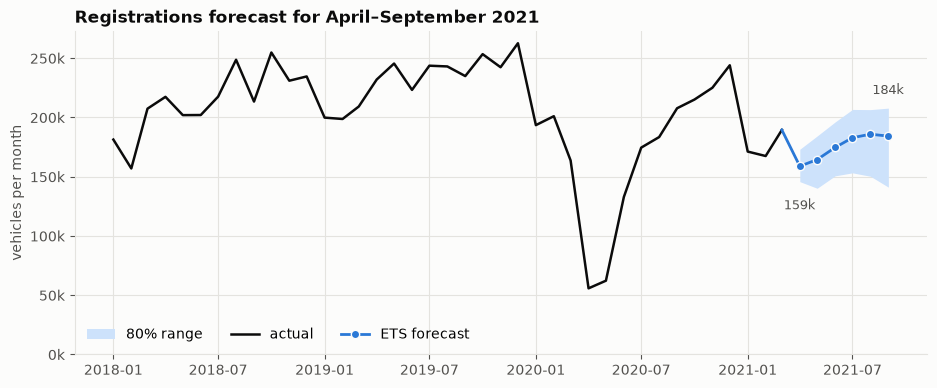

In [22]:
history = total.loc['2018-01-01':]
fig, ax = plt.subplots(figsize=(11, 4.2))
x_fc = months
ax.fill_between(x_fc, forecast['low (10%)'], forecast['high (90%)'], color='#cde2fb', lw=0, label='80% range')
ax.plot(history.index, history, color=INK, lw=1.8, label='actual')
ax.plot([history.index[-1], *x_fc], [history.iloc[-1], *forecast['forecast']], color=BLUE, lw=2,
        marker='o', ms=6, markevery=list(range(1, HORIZON + 1)), markeredgecolor=SURFACE, label='ETS forecast')
for m, v, label_y in [(x_fc[0], forecast['forecast'].iloc[0], forecast['low (10%)'].iloc[0]),
                      (x_fc[-1], forecast['forecast'].iloc[-1], forecast['high (90%)'].iloc[-1])]:
    ax.annotate(f'{v / 1000:,.0f}k', (m, label_y), xytext=(0, -12 if label_y < v else 8), textcoords='offset points',
                ha='center', va='top' if label_y < v else 'bottom', color=INK_2, fontsize=9)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, None)
ax.set_title('Registrations forecast for April–September 2021')
ax.set_ylabel('vehicles per month')
ax.legend(loc='lower left', ncol=3)
plt.show()

- After a weak first quarter of 2021 (171 to 189 thousand a month), ETS expects registrations to recover gradually, from about **159 thousand in April to about 185 thousand in August and September**.
- That is still below the 2019 average of 232 thousand a month.
- The range is wider on the downside, especially further ahead, because the largest past misses were sudden drops (the 2015 recession and the 2020 pandemic).

## 9. Conclusions and next steps

**Conclusions**

1. **A simple, well-tested model works.**
   - Exponential smoothing on registrations per working day, refit every month, forecasts the next month within about 5% and six months ahead within about 12% in normal times.
   - That is 40% less error than repeating the last month, and about 15% less than repeating the same month last year.
2. **The working-day calendar matters.** Dividing by working days removes a quarter of the seasonal variation (8.8% → 6.7%), so every model forecasts registrations per working day.
3. **The IBGE indicators did not help much.** By the time industry and retail are published, about two months later, most of their information is already in the registrations. They improved the Ridge model slightly but did not beat ETS when the model was chosen. On the test period Ridge + IBGE indicators was marginally ahead (8.2% vs 8.7%), a gap within the month-to-month noise.
4. **Shocks are outside the reach of the model.** The pandemic, like the 2015 recession, is a reason to pair the statistical forecast with judgment and scenarios when the economy turns.
5. **Segments:** the same approach works for cars, light commercials and trucks. Buses need a different input, such as fleet-renewal programs and public tenders.

**Next steps**

- Add indicators that are published faster or that look forward: consumer and business confidence (FGV), interest rates and credit approvals, and vehicle financing data (B3). These are available before the month is over.
- Forecast the segments together, so that they add up to the total.
- Test an average of ETS and Ridge + IBGE indicators. The two were close on the test period, and an average is often more robust than either model alone.
- Refresh the data and run the backtest every month to monitor the error.